# TP Final Integrador · Entrenamiento del modelo

**Seminario de Actualización · IFTS N.º 18 · 2026**

**Problema:** a partir de los hábitos de uso del celular de un/a adolescente, estimar si tiene un **nivel de adicción alto** (el máximo de la escala) y con qué probabilidad.

## 1. Librerías

In [1]:
import os
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)

scikit-learn: 1.9.1
pandas: 3.0.6


## 2. El dataset

**Fuente:** *Teen Smartphone Usage and Addiction Impact Dataset*, publicado en Kaggle por sumedh1507:
https://www.kaggle.com/datasets/sumedh1507/teen-phone-addiction

In [2]:
RUTA_DATASET = os.path.join("..", "teen_phone_addiction_dataset.csv")
df = pd.read_csv(RUTA_DATASET)

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (3000, 25)


,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      3000 non-null   int64  
 1   Name                    3000 non-null   str    
 2   Age                     3000 non-null   int64  
 3   Gender                  3000 non-null   str    
 4   Location                3000 non-null   str    
 5   School_Grade            3000 non-null   str    
 6   Daily_Usage_Hours       3000 non-null   float64
 7   Sleep_Hours             3000 non-null   float64
 8   Academic_Performance    3000 non-null   int64  
 9   Social_Interactions     3000 non-null   int64  
 10  Exercise_Hours          3000 non-null   float64
 11  Anxiety_Level           3000 non-null   int64  
 12  Depression_Level        3000 non-null   int64  
 13  Self_Esteem             3000 non-null   int64  
 14  Parental_Control        3000 non-null   int64  
 15

In [4]:
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
df.describe().T.round(2)

Valores nulos: 0
Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
ID,3000.0,1500.50,866.17,1.0,750.75,1500.5,2250.25,3000.0
Age,3000.0,15.97,1.99,13.0,14.00,16.0,18.00,19.0
Daily_Usage_Hours,3000.0,5.02,1.96,0.0,3.70,5.0,6.40,11.5
Sleep_Hours,3000.0,6.49,1.49,3.0,5.50,6.5,7.50,10.0
Academic_Performance,3000.0,74.95,14.68,50.0,62.00,75.0,88.00,100.0
Social_Interactions,3000.0,5.10,3.14,0.0,2.00,5.0,8.00,10.0
Exercise_Hours,3000.0,1.04,0.73,0.0,0.50,1.0,1.50,4.0
Anxiety_Level,3000.0,5.59,2.89,1.0,3.00,6.0,8.00,10.0
Depression_Level,3000.0,5.46,2.87,1.0,3.00,5.0,8.00,10.0
Self_Esteem,3000.0,5.55,2.86,1.0,3.00,6.0,8.00,10.0


Saco las columnas que no sirven para el entrenamiento:
- `ID`,`Name`,`Location`

In [5]:
for col in ["Gender", "Location", "School_Grade", "Phone_Usage_Purpose"]:
    print(f"{col}: {df[col].nunique()} valores distintos")

Gender: 3 valores distintos
Location: 2726 valores distintos
School_Grade: 6 valores distintos
Phone_Usage_Purpose: 5 valores distintos


## 3. El target que voy a usar: Addiction_Level

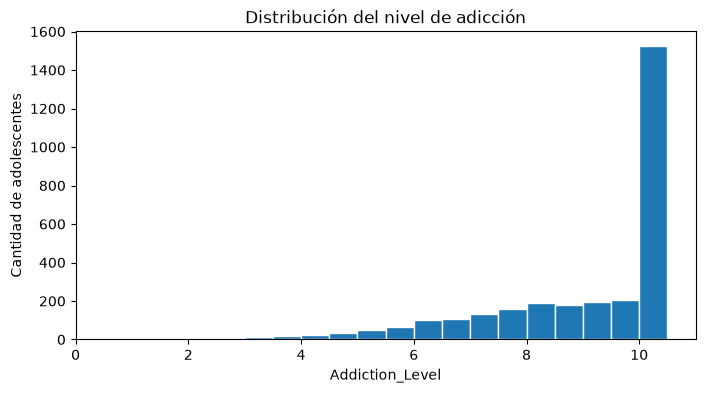

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Addiction_Level"], bins=np.arange(0.5, 10.6, 0.5), edgecolor="white")
ax.set_xlabel("Addiction_Level")
ax.set_ylabel("Cantidad de adolescentes")
ax.set_title("Distribución del nivel de adicción")
plt.show()

In [7]:
# quiero ver cual es la proporción de adolescentes con nivel de adicción exactamente 10
print("Proporción con nivel exactamente 10:", round((df["Addiction_Level"] == 10).mean(), 3))

Proporción con nivel exactamente 10: 0.508


La distribución está muy cargada hacia arriba. La mitad de los casos (51%) tiene **exactamente 10**, así que conviene hacer una clasificación bonaria: >=10 es adicto, <10 no adicto.

Ventajas de este corte:
- Las dos clases quedan balanceadas.
- El modelo devuelve una probabilidad, que se puede mostrar en la web.

In [8]:
df["Adiccion_Alta"] = (df["Addiction_Level"] >= 10).astype(int)
df["Adiccion_Alta"].value_counts(normalize=True).round(3)

Adiccion_Alta
1    0.508
0    0.492
Name: proportion, dtype: float64

## 4. Elección de las features

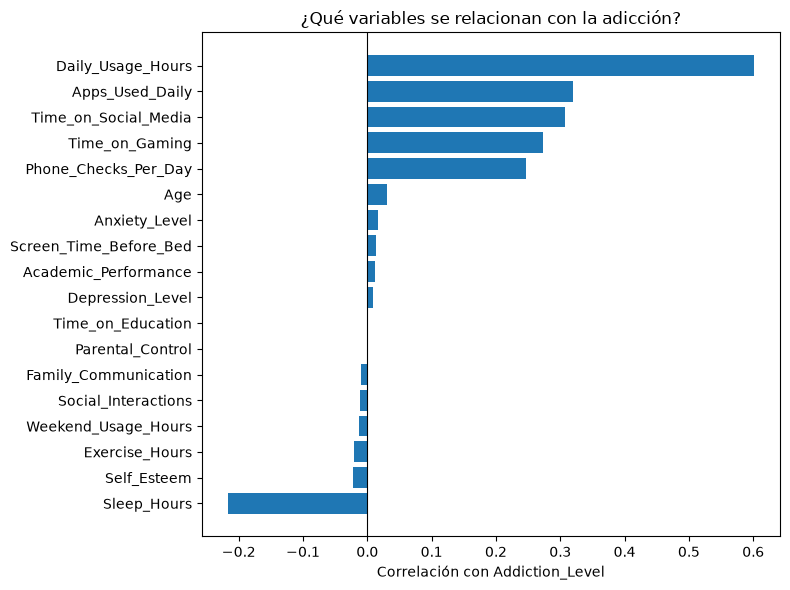

In [9]:
numericas = df.select_dtypes("number").drop(columns=["ID", "Adiccion_Alta"])
correlaciones = numericas.corr()["Addiction_Level"].drop("Addiction_Level").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(correlaciones.index, correlaciones.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlación con Addiction_Level")
ax.set_title("¿Qué variables se relacionan con la adicción?")
plt.tight_layout()
plt.show()

In [10]:
# Las variables categóricas, vemos si cambia la proporción de adicción alta entre grupos
for col in ["Gender", "School_Grade", "Phone_Usage_Purpose"]:
    print(df.groupby(col)["Adiccion_Alta"].mean().round(3), "\n")

Gender
Female    0.512
Male      0.516
Other     0.495
Name: Adiccion_Alta, dtype: float64 

School_Grade
10th    0.487
11th    0.528
12th    0.512
7th     0.515
8th     0.494
9th     0.511
Name: Adiccion_Alta, dtype: float64 

Phone_Usage_Purpose
Browsing        0.504
Education       0.512
Gaming          0.526
Other           0.529
Social Media    0.468
Name: Adiccion_Alta, dtype: float64 



**Lectura:** solo seis variables muestran relación clara con la adicción:

| Variable | Qué mide | Relación |
|---|---|---|
| `Daily_Usage_Hours` | horas de uso diario | + (la más fuerte) |
| `Apps_Used_Daily` | cantidad de apps usadas por día | + |
| `Time_on_Social_Media` | horas en redes sociales | + |
| `Time_on_Gaming` | horas en juegos | + |
| `Phone_Checks_Per_Day` | veces que mira el celular por día | + |
| `Sleep_Hours` | horas de sueño | − (más sueño, menos adicción) |

In [11]:
FEATURES = [
    "Daily_Usage_Hours",
    "Sleep_Hours",
    "Time_on_Social_Media",
    "Time_on_Gaming",
    "Phone_Checks_Per_Day",
    "Apps_Used_Daily",
]
TARGET = "Adiccion_Alta"

X = df[FEATURES]
y = df[TARGET]

# Rangos de cada variable: sirven después para validar el formulario y la API
X.describe().T[["min", "max"]]

,min,max
Daily_Usage_Hours,0.0,11.5
Sleep_Hours,3.0,10.0
Time_on_Social_Media,0.0,5.0
Time_on_Gaming,0.0,4.0
Phone_Checks_Per_Day,20.0,150.0
Apps_Used_Daily,5.0,20.0


## 5. División entrenamiento / prueba

80% para entrenar y 20% para evaluar.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Proporción de clase 1 → train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Entrenamiento: (2400, 6) | Prueba: (600, 6)
Proporción de clase 1 → train: 0.508 | test: 0.508


## 6. Modelos

Comparo dos modelos de clasificación:

1. **Regresión logística**
2. **Random Forest**

**Métrica principal:** F1 (promedio *macro* de las dos clases), que combina precisión y recall. También exactitud (*accuracy*) y AUC-ROC.

In [13]:
modelos = {
    "Regresión logística": Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, random_state=42
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

for nombre, modelo in modelos.items():
    # Validación cruzada sobre entrenamiento
    f1_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="f1_macro")

    # Entrenamiento final y evaluación sobre el conjunto de prueba
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]

    resultados.append({
        "Modelo": nombre,
        "F1 CV (media)": f1_cv.mean(),
        "F1 CV (desvío)": f1_cv.std(),
        "Accuracy test": accuracy_score(y_test, pred),
        "F1 test": f1_score(y_test, pred, average="macro"),
        "AUC-ROC test": roc_auc_score(y_test, proba),
    })

tabla = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabla

,F1 CV (media),F1 CV (desvío),Accuracy test,F1 test,AUC-ROC test
Modelo,,,,,
Regresión logística,0.995,0.002,0.992,0.992,1.000
Random Forest,0.916,0.013,0.907,0.906,0.976


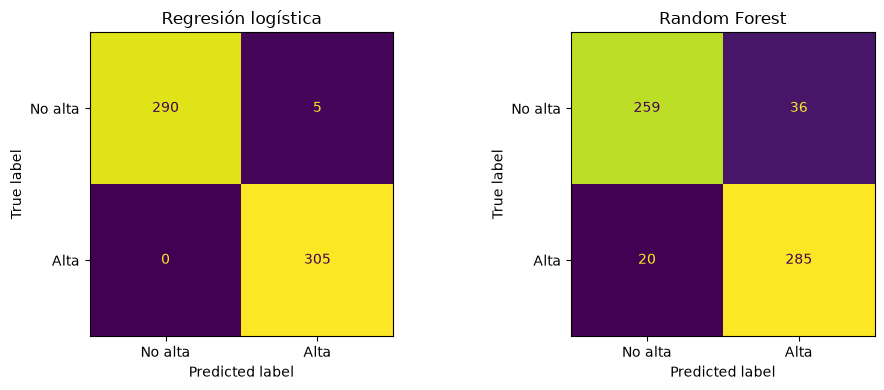

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test, ax=ax, colorbar=False,
        display_labels=["No alta", "Alta"]
    )
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [15]:
print("Regresión logística · reporte por clase\n")
print(classification_report(y_test, modelos["Regresión logística"].predict(X_test),
                            target_names=["No alta", "Alta"]))

Regresión logística · reporte por clase

              precision    recall  f1-score   support

     No alta       1.00      0.98      0.99       295
        Alta       0.98      1.00      0.99       305

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



In [16]:
# Peso que tendría cada modelo al exportarlo (sin guardarlo en disco)
import io
for nombre, modelo in modelos.items():
    buffer = io.BytesIO()
    joblib.dump(modelo, buffer)
    print(f"{nombre}: {len(buffer.getvalue()) / 1e6:.4f} MB")

Regresión logística: 0.0019 MB
Random Forest: 2.1571 MB


**Interpretación:** la regresión logística logra F1 ≈ 0,99 en prueba y la validación cruzada da casi lo mismo, o sea que el resultado es estable y no depende de cómo se dividieron los datos. El Random Forest queda en F1 ≈ 0,91: aproxima la frontera con cortes escalonados y acá la frontera es una línea recta. Como las clases están balanceadas, accuracy y F1 cuentan lo mismo.

**Modelo elegido: regresión logística.** Es la más precisa, la más liviana (unos 0,002 MB contra unos 2 MB del RF, más de mil veces menos) y se puede interpretar. Un archivo chico carga rápido y entra holgado en la memoria de un plan gratuito.

In [19]:
# Si el puntaje sale de una fórmula, una regresión lineal sobre los casos que no
# llegan al tope (nivel < 10) debería ajustar casi perfecto
sin_tope = df[df["Addiction_Level"] < 10]
reg = LinearRegression().fit(sin_tope[FEATURES], sin_tope["Addiction_Level"])

print("R² =", round(reg.score(sin_tope[FEATURES], sin_tope["Addiction_Level"]), 4))
pd.Series(reg.coef_, index=FEATURES).round(2).to_frame("Coeficiente")

R² = 0.9997


,Coeficiente
Daily_Usage_Hours,1.00
Sleep_Hours,-0.50
Time_on_Social_Media,1.00
Time_on_Gaming,1.00
Phone_Checks_Per_Day,0.02
Apps_Used_Daily,0.20


Un F1 de 0,99 es raro con datos reales. Revisando los datos encontré que el puntaje de adicción sale de una fórmula: uso diario + redes + juegos − ½ horas de sueño, más un poco por chequeos y apps, recortado entre 1 y 10. Es decir, **el dataset es sintético**, aunque Kaggle no lo aclara. Por eso un modelo lineal acierta casi siempre y por eso ansiedad o depresión no influyen.

## 7. Exportación con joblib

Guardo el `Pipeline` completo (escalado + modelo) en `app/modelo/modelo.joblib`. Al guardar el pipeline entero, la API recibe los valores tal como los escribe la persona en el formulario y no tiene que repetir el escalado.

In [17]:
modelo_final = modelos["Regresión logística"]   

RUTA_MODELO = os.path.join("..", "app", "modelo", "modelo.joblib")
os.makedirs(os.path.dirname(RUTA_MODELO), exist_ok=True)

joblib.dump(modelo_final, RUTA_MODELO)

print("Modelo guardado en:", RUTA_MODELO)
print("Versión de scikit-learn:", sklearn.__version__)
print("Peso del archivo:", round(os.path.getsize(RUTA_MODELO) / 1e6, 4), "MB")

Modelo guardado en: ..\app\modelo\modelo.joblib
Versión de scikit-learn: 1.9.1
Peso del archivo: 0.0019 MB


In [18]:
# Verificación: se vuelve a cargar el archivo como lo hará la API y se repite la predicción
entrada = pd.DataFrame([{
    "Daily_Usage_Hours": 5.5, "Sleep_Hours": 6.5, "Time_on_Social_Media": 2.5,
    "Time_on_Gaming": 1.5, "Phone_Checks_Per_Day": 90, "Apps_Used_Daily": 13,
}])[FEATURES]

modelo_cargado = joblib.load(RUTA_MODELO)
print("Predicción con el modelo cargado:",
      int(modelo_cargado.predict(entrada)[0]),
      "| probabilidad:", round(float(modelo_cargado.predict_proba(entrada)[0, 1]), 3))

Predicción con el modelo cargado: 1 | probabilidad: 0.951
